<table align="left">
  <td>
    <a href="https://colab.research.google.com/github/Insight-Sogang-Univ/insight-16th/blob/main/advanced/template/session07/assignment_recsys.ipynb" target="_parent">
      <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
    </a>
  </td>
</table>

# <span style="color:black; background-color:#F5F5F5;"> 🍀 **추천 시스템 (Recommendation System) 과제** </span>

## **1. 추천 시스템 기본 개념**

### 1-1. 빈칸에 들어갈 말을 순서대로 작성해주세요.
자카드 유사도는 아이템 집합간의 OOO 크기를 이용하여 측정
<br>코사인 유사도는 아이템의 벡터 사이의 OO를 이용하여 측정
<br>유클리디안 거리는 아이템의 벡터 사이의 OO를 이용하여 측정
<br>피어슨 상관계수는 아이템의 벡터간 OO OO OO를 이용하여 측정

답: 교집합, 각도, 거리, 선형 상관 관계


### 1-2. T/F를 골라주시고, **F일 경우 이유까지** 함께 작성해주세요.
(1) 평갓값 행렬은 수집한 사용자의 아이템 선호도를 정량적으로 나타낸 것으로, 사용자 X 아이템으로 계산한다. 이렇게 발견된 평점은 밀집 행렬의 형태를 띠고 있어 명시되지 않은 평점을 대체하는 것이 가능하다<br>

(2) TF-IDF는 특정 문서에 자주 등장하는 단어일수록, 그리고 전체 문서에 걸쳐 많은 문서에 등장하는 단어일수록 높은 값을 부여하여 해당 단어를 중요한 특징으로 취급한다.<br>

(3) Memory-based는 모든 데이터를 이용하기에, 항상 최신 데이터를 반영해 추천 가능하지만, 매번 모든 데이터에서 비슷한 user나 item을 찾아야 해서 오래 걸린다.

답:
- (1) F: 실제 평가값 행렬은 대부분 칸이 비어 있는 희소 행렬임. 밀집 행렬 아님
- (2) F: 많은 문서에 등장하는 단어일수록 IDF가 작아져서 TF-IDF 값이 낮아짐. 특정 문서에만 자주 나오는 단어가 높은 값 받음
- (3) T

---

우선, 두 가지 방법의 협업 필터링을 구현해 보려고 합니다!  
(내용 기반 필터링은 실습에서 했으니까요)

## **2. Item-Based Collaborative Filtering**

---

In [5]:
import pandas as pd
import numpy as np

In [6]:
ratings= pd.read_csv("chicken_1516th.csv", index_col='이름') # 파일 불러오기
ratings

,(BHC) 뿌링클,(BHC) 맛초킹,(BHC) 레드킹,(교촌) 교촌콤보,(교촌) 허니콤보,(교촌) 레드콤보,(굽네) 고추바사삭,(굽네) 볼케이노,(굽네) 갈비천왕,(BBQ) 황금올리브,...,(60계) 간지치킨,(바른치킨) 대세레드,(바른치킨) 현미바사삭,(바른치킨) 통곡물간장,(노랑통닭) 알싸한마늘치킨,(노랑통닭) 뿌리노랑치킨,(노랑통닭) 칼칼한청양치킨,(후참잘) 후라이드치킨,(후참잘) 양념치킨,(후참잘) 간장치킨
이름,,,,,,,,,,,,,,,,,,,,,
권유철,4,3,3,5,5,4,5,2,2,5,...,0,0,4,4,4,0,0,4,1,4
김민아,3,2,1,3,3,3,3,1,0,3,...,0,0,2,0,0,0,0,1,0,0
김지윤,3,0,0,5,2,3,5,5,4,5,...,5,3,4,0,0,0,0,3,0,0
김진하,5,2,3,5,5,3,2,3,2,5,...,0,1,4,5,5,0,0,5,4,3
김희연,5,5,2,3,5,5,5,4,4,5,...,4,3,3,3,5,3,2,2,2,2
류시현,3,3,0,0,2,1,3,0,3,3,...,3,3,1,1,0,0,0,0,0,0
방서영,2,0,0,4,4,3,5,0,0,5,...,0,0,3,3,3,0,0,0,0,0
손영현,1,0,0,0,1,0,4,4,0,5,...,1,0,0,0,2,0,0,0,0,0
오규원,1,0,0,3,4,3,4,0,0,5,...,0,0,0,0,3,3,0,4,0,0


### **2-1. 아이템 유사도 계산**

In [7]:
from sklearn.metrics.pairwise import cosine_similarity

# 유사도 계산을 위해 결측치를 0으로 대체
ratings.fillna(0, inplace=True)

# 유사도 계산
item_similarity = cosine_similarity(ratings.T)

# 아이템 유사도 DataFrame 생성
# data는 item_similarity, index는 ratings.T.index, columns는 ratings.T.index로 지정합니다.
item_similarity = pd.DataFrame(data=item_similarity,
                            index=ratings.T.index,
                            columns=ratings.T.index)

item_similarity.head()

,(BHC) 뿌링클,(BHC) 맛초킹,(BHC) 레드킹,(교촌) 교촌콤보,(교촌) 허니콤보,(교촌) 레드콤보,(굽네) 고추바사삭,(굽네) 볼케이노,(굽네) 갈비천왕,(BBQ) 황금올리브,...,(60계) 간지치킨,(바른치킨) 대세레드,(바른치킨) 현미바사삭,(바른치킨) 통곡물간장,(노랑통닭) 알싸한마늘치킨,(노랑통닭) 뿌리노랑치킨,(노랑통닭) 칼칼한청양치킨,(후참잘) 후라이드치킨,(후참잘) 양념치킨,(후참잘) 간장치킨
(BHC) 뿌링클,1.000000,0.692836,0.712930,0.856836,0.897079,0.815319,0.780076,0.728011,0.686305,0.887981,...,0.550795,0.584486,0.822226,0.749179,0.724254,0.547426,0.527945,0.704225,0.627324,0.663856
(BHC) 맛초킹,0.692836,1.000000,0.794430,0.586272,0.634623,0.694882,0.640268,0.533443,0.560178,0.661500,...,0.592224,0.611604,0.568722,0.449799,0.752140,0.470882,0.544949,0.589815,0.545058,0.678454
(BHC) 레드킹,0.712930,0.794430,1.000000,0.647150,0.630204,0.639199,0.593673,0.533366,0.428086,0.630380,...,0.441261,0.328975,0.603633,0.537086,0.828145,0.454805,0.608698,0.626866,0.661823,0.686495
(교촌) 교촌콤보,0.856836,0.586272,0.647150,1.000000,0.938127,0.878475,0.818267,0.688034,0.552607,0.870739,...,0.419026,0.509981,0.862511,0.741126,0.697134,0.425140,0.372954,0.709341,0.548352,0.587546
(교촌) 허니콤보,0.897079,0.634623,0.630204,0.938127,1.000000,0.863602,0.865480,0.669711,0.607088,0.890193,...,0.383356,0.567405,0.829431,0.753431,0.726836,0.545369,0.382891,0.698037,0.539614,0.586641


### 본격적인 시작에 앞서, 여러분이 마케팅팀이라고 가정했을 때, 교촌 허니콤보와 유사한 선호도를 가진 치킨끼리 묶어서 특가 할인행사를 시행하려고 합니다!<br>
# 유사한 선호도 Top 3를 묶어서 특가 할인행사 대상을 선별해주세요!

#### **2-1-1. 특가 할인행사 대상은 어떻게 도출되었나요?**

답: 평점표를 전치해서 치킨끼리 코사인 유사도 계산함. 허니콤보 열을 유사도 높은 순으로 정렬하고, 자기 자신 빼고 상위 3개 뽑음
→ 교촌콤보(0.938), 뿌링클(0.897), 황금올리브(0.890)



In [8]:
def get_similar_item(title):
    return item_similarity[title].sort_values(ascending=False)[1:4]

get_similar_item("(교촌) 허니콤보").head(3)

,(교촌) 허니콤보
(교촌) 교촌콤보,0.938127
(BHC) 뿌링클,0.897079
(BBQ) 황금올리브,0.890193


#### **2-1-2. 각 치킨별 추천 치킨(아이템 유사도 기준) 만들기**

In [9]:
# 치킨 리스트
chicken_list = list(item_similarity.index)

# 새로운 데이터프레임을 만들기 위한 빈 리스트 초기화
recommendations = []

# 각 치킨에 대해 유사한 항목 찾기
for chicken in chicken_list:
    similar_items = get_similar_item(chicken).head(3)

    # '추천 치킨'이라는 새로운 칼럼을 만들어 데이터프레임에 추가
    recommendations.append({
        'Chicken': chicken,
        'Recommendations': ', '.join(similar_items.index)
    })

# 결과 데이터프레임 생성
result_df = pd.DataFrame(recommendations)

# 결과 출력
result_df

,Chicken,Recommendations
0,(BHC) 뿌링클,"(교촌) 허니콤보, (BBQ) 황금올리브, (교촌) 교촌콤보"
1,(BHC) 맛초킹,"(BHC) 레드킹, (노랑통닭) 알싸한마늘치킨, (교촌) 레드콤보"
2,(BHC) 레드킹,"(노랑통닭) 알싸한마늘치킨, (BHC) 맛초킹, (네네) 스노윙"
3,(교촌) 교촌콤보,"(교촌) 허니콤보, (교촌) 레드콤보, (BBQ) 황금올리브"
4,(교촌) 허니콤보,"(교촌) 교촌콤보, (BHC) 뿌링클, (BBQ) 황금올리브"
5,(교촌) 레드콤보,"(교촌) 교촌콤보, (교촌) 허니콤보, (BBQ) 황금올리브"
6,(굽네) 고추바사삭,"(BBQ) 황금올리브, (교촌) 허니콤보, (교촌) 교촌콤보"
7,(굽네) 볼케이노,"(굽네) 고추바사삭, (BBQ) 황금올리브, (굽네) 갈비천왕"
8,(굽네) 갈비천왕,"(굽네) 볼케이노, (바른치킨) 대세레드, (BHC) 뿌링클"
9,(BBQ) 황금올리브,"(굽네) 고추바사삭, (교촌) 허니콤보, (BHC) 뿌링클"


### **2-2. 아이템 평점 예측**

In [10]:
def predict_rating(ratings, item_similarity):
    # 평가한 항목은 1, 미평가(0)는 0으로 마스킹
    ratings_binary = (ratings > 0).astype(float)

    # @는 파이썬에서 행렬곱을 뜻합니다.
    sum_sr = ratings @ item_similarity
    sum_s_abs = ratings_binary @ abs(item_similarity)
    sum_s_abs[sum_s_abs == 0] = 1e-9         # 0으로 나누기 방지
    ratings_pred =  sum_sr / sum_s_abs
    return ratings_pred

# 아이템별 평점 예측
ratings_pred = predict_rating(ratings.values, item_similarity.values)

# 예측한 평점에 대한 DataFrame 생성
# 행·열 이름은 원래 평점표(ratings)와 똑같이 맞춰 주세요
ratings_pred_matrix = pd.DataFrame(data=ratings_pred,
                                    index= ratings.index,
                                    columns = ratings.columns)
ratings_pred_matrix.head(5)

,(BHC) 뿌링클,(BHC) 맛초킹,(BHC) 레드킹,(교촌) 교촌콤보,(교촌) 허니콤보,(교촌) 레드콤보,(굽네) 고추바사삭,(굽네) 볼케이노,(굽네) 갈비천왕,(BBQ) 황금올리브,...,(60계) 간지치킨,(바른치킨) 대세레드,(바른치킨) 현미바사삭,(바른치킨) 통곡물간장,(노랑통닭) 알싸한마늘치킨,(노랑통닭) 뿌리노랑치킨,(노랑통닭) 칼칼한청양치킨,(후참잘) 후라이드치킨,(후참잘) 양념치킨,(후참잘) 간장치킨
이름,,,,,,,,,,,,,,,,,,,,,
권유철,3.690581,3.645594,3.656167,3.743648,3.735409,3.748916,3.715523,3.592914,3.551170,3.715980,...,3.570864,3.636632,3.757354,3.759986,3.697722,3.647314,3.567656,3.677600,3.551325,3.595715
김민아,2.431660,2.361589,2.325710,2.459960,2.470980,2.431873,2.456530,2.369556,2.387240,2.453300,...,2.345063,2.436645,2.440334,2.448735,2.392263,2.455492,2.326509,2.352476,2.320245,2.318276
김지윤,3.815911,3.820585,3.827375,3.813406,3.795880,3.793387,3.853375,3.882565,3.856046,3.839131,...,3.925602,3.837442,3.812790,3.753353,3.815217,3.818416,3.859254,3.777904,3.795632,3.793269
김진하,3.745811,3.606282,3.736345,3.762198,3.745803,3.723506,3.656725,3.620666,3.543770,3.702536,...,3.544682,3.451074,3.773552,3.870766,3.739109,3.675274,3.722788,3.738038,3.738073,3.678192
김희연,3.460803,3.476600,3.414655,3.423740,3.445883,3.466400,3.458404,3.446114,3.515188,3.441654,...,3.562994,3.511769,3.439601,3.447351,3.424383,3.380596,3.408713,3.361429,3.314121,3.336886


#### **2-2-1. 평점 예측 성능 평가**

평가 지표들을 이용하여 성능을 평가해보고자 합니다.

- **MAE(Mean Absolute Error)** : 모델의 예측값과 실제값의 차이의 절대값의 평균, 절대값을 취하기 때문에 가장 직관적으로 알 수 있는 지표이다.
- **MSE(Mean Squared Error)** : 모델의 예측값과 실제값 차이를 제곱해서 평균 낸 값, 제곱을 하기 때문에 MAE와 달리 특이치(Outlier)에 민감하다.
- **RMSE(Root Mean Squared Error)**: MSE에 루트를 씌워 사용, RMSE를 사용하면 오류 지표를 실제값과 유사한 단위로 다시 변환하여 해석을 쉽게 한다.

In [11]:
# 평점 예측 성능 평가 함수 (MAE)
from sklearn.metrics import mean_absolute_error

def get_mae(pred, actual):
    pred=pred[actual.nonzero()].flatten()
    actual=actual[actual.nonzero()].flatten()
    return mean_absolute_error(pred, actual)

MAE=get_mae(ratings_pred_matrix.values, ratings.values) # 위에서 정의한 예측값을 넣으세요!
print(f'아이템 기반 모든 인접 이웃 MAE: {MAE:.4f}')

아이템 기반 모든 인접 이웃 MAE: 0.8882


In [12]:
# 평점 예측 성능 평가 함수 (MSE)
from sklearn.metrics import mean_squared_error

def get_mse(pred, actual):
    pred = pred[actual.nonzero()].flatten()
    actual = actual[actual.nonzero()].flatten()
    return mean_squared_error(pred, actual)

MSE = get_mse(ratings_pred_matrix.values, ratings.values)
print(f'아이템 기반 모든 인접 이웃 MSE: {MSE:.4f}')

아이템 기반 모든 인접 이웃 MSE: 1.1272


In [13]:
# 평점 예측 성능 평가 함수 (RMSE)
# MSE에 제곱근(np.sqrt)을 씌우면 RMSE
from sklearn.metrics import mean_squared_error

def get_rmse(pred, actual):
    pred = pred[actual.nonzero()].flatten()
    actual = actual[actual.nonzero()].flatten()
    return np.sqrt(mean_squared_error(pred, actual))  # 제곱근으로 RMSE 직접 계산

RMSE = get_rmse(ratings_pred_matrix.values, ratings.values)
print(f'아이템 기반 모든 인접 이웃 RMSE: {RMSE:.4f}')

아이템 기반 모든 인접 이웃 RMSE: 1.0617


#### **2-2-2. 치킨 추천**
본인에게 치킨을 추천해볼까요? -> ***에 이름을 입력해주세요!

In [14]:
# 본인이 높은 평점을 준 치킨
user_rated_food = ratings.loc['최영효', :] # 이름을 입력해봅시다
user_rated_food[user_rated_food > 0].sort_values(ascending=False)[:5]

,최영효
(BHC) 맛초킹,3
(교촌) 레드콤보,3
(교촌) 허니콤보,3
(후참잘) 간장치킨,3
(노랑통닭) 알싸한마늘치킨,3


In [15]:
# 본인이 평가하지 않은 치킨

def never_try_food(ratings, userId):
    user_rating = ratings.loc[userId,:]
    never_food_list = user_rating[user_rating == 0].index.tolist()
    food_list = ratings.columns.tolist()
    never_list = [food for food in food_list if food in never_food_list]
    return never_list

unrated_food = never_try_food(ratings, '최영효') # 이름을 입력해볼까요?
unrated_food

['(BHC) 레드킹',
 '(BBQ) 자메이카통다리',
 '(처갓집) 블랙라벨',
 '(처갓집) XO양념치킨',
 '(처갓집) 트러플슈프림',
 '(60계) 크크크치킨',
 '(60계) 하하핫치킨',
 '(60계) 간지치킨',
 '(노랑통닭) 뿌리노랑치킨',
 '(노랑통닭) 칼칼한청양치킨',
 '(후참잘) 양념치킨']

In [16]:
# 본인이 평가하지 않은 치킨에 대해 직접 예측한 평점을 바탕으로 음식 추천!

def recomm_food_by_userid(pred_df, userId, never_list, top_n=10):
    recomm_food = pred_df.loc[userId, never_list].sort_values(ascending=False)[:top_n]
    return recomm_food

recommend_food = recomm_food_by_userid(ratings_pred_matrix, '최영효', unrated_food, top_n=5) # 이름을 입력해보아요
recommend_food

,최영효
(노랑통닭) 뿌리노랑치킨,2.473185
(60계) 하하핫치킨,2.457753
(후참잘) 양념치킨,2.432226
(60계) 간지치킨,2.424580
(노랑통닭) 칼칼한청양치킨,2.420823


In [17]:
# 앞에서 만든 함수들을 학회원 전체에 적용해봅시다!
# 각 학회원이 안 먹어본 치킨 중, 아이템 기반 CF로 예측한 평점이 가장 높은 치킨 1개와 그 예측 평점을 정리합니다.

name = list(ratings.index)
best_recommend=[]
best_score =[]
for word in name:
    user_rated_food = ratings.loc[word, :] # 각 학회원이 평가하지 않은 치킨 목록을 뽑고
    user_rated_food[user_rated_food > 0].sort_values(ascending=False)[:5]
    unrated_food = never_try_food(ratings, word)
    best_recommend.append(list(recomm_food_by_userid(ratings_pred_matrix, word, unrated_food, top_n=1).index)) # 그중 예측 평점이 가장 높은 치킨 1개를 골라
    best_score.append(list(recomm_food_by_userid(ratings_pred_matrix, word, unrated_food, top_n=1).values))

present1 = pd.DataFrame({'이름':name,'추천치킨_Item':best_recommend,'평점_Item':best_score}) # 이름 / 추천 치킨 / 예측 평점을 하나의 표로 정리합니다
present1

,이름,추천치킨_Item,평점_Item
0,권유철,[(네네) 청양마요],[3.763880502860041]
1,김민아,[(네네) 오리엔탈파닭],[2.481071300773466]
2,김지윤,[(처갓집) 트러플슈프림],[3.8691159790052887]
3,김진하,[(노랑통닭) 칼칼한청양치킨],[3.7227876045339854]
4,김희연,[(60계) 하하핫치킨],[3.3853589793893435]
5,류시현,[(노랑통닭) 칼칼한청양치킨],[2.508026222559146]
6,방서영,[(바른치킨) 대세레드],[3.42341371687879]
7,손영현,[(네네) 오리엔탈파닭],[2.7904614934244205]
8,오규원,[(바른치킨) 대세레드],[3.4476777142602297]
9,이수빈,[(노랑통닭) 뿌리노랑치킨],[3.4025360695963633]


---

## **3. User-based Collaborative Filtering**


아이템 기반 CF가 "이 치킨을 좋아한 사람들은 저 치킨도 좋아하더라"였다면,  
사용자 기반 CF는 **"나와 입맛이 비슷한 사람들이 좋아한 치킨"** 을 추천하는 방식입니다.

> 💡 강의에서 배운 사용자 기반 접근을 떠올려 보세요!
> 나와 유사도가 가장 높은 **Top-N명을 이웃으로 선정** → 이웃들의 평점을 **유사도로 가중평균** → 예측 평점이 높은 아이템 추천

이번 파트에서는
- 학회원 간 유사도를 구해 각자의 **이웃 5명**을 찾고,
- 이웃들의 평점으로 **아직 안 먹어본 치킨의 평점을 예측**한 뒤,
- 이 예측 평점을 활용해 **버디조 회식 메뉴**까지 정해봅니다!

---

In [18]:
# 다시 불러오기
ratings = pd.read_csv("chicken_1516th.csv",index_col='이름')
ratings

,(BHC) 뿌링클,(BHC) 맛초킹,(BHC) 레드킹,(교촌) 교촌콤보,(교촌) 허니콤보,(교촌) 레드콤보,(굽네) 고추바사삭,(굽네) 볼케이노,(굽네) 갈비천왕,(BBQ) 황금올리브,...,(60계) 간지치킨,(바른치킨) 대세레드,(바른치킨) 현미바사삭,(바른치킨) 통곡물간장,(노랑통닭) 알싸한마늘치킨,(노랑통닭) 뿌리노랑치킨,(노랑통닭) 칼칼한청양치킨,(후참잘) 후라이드치킨,(후참잘) 양념치킨,(후참잘) 간장치킨
이름,,,,,,,,,,,,,,,,,,,,,
권유철,4,3,3,5,5,4,5,2,2,5,...,0,0,4,4,4,0,0,4,1,4
김민아,3,2,1,3,3,3,3,1,0,3,...,0,0,2,0,0,0,0,1,0,0
김지윤,3,0,0,5,2,3,5,5,4,5,...,5,3,4,0,0,0,0,3,0,0
김진하,5,2,3,5,5,3,2,3,2,5,...,0,1,4,5,5,0,0,5,4,3
김희연,5,5,2,3,5,5,5,4,4,5,...,4,3,3,3,5,3,2,2,2,2
류시현,3,3,0,0,2,1,3,0,3,3,...,3,3,1,1,0,0,0,0,0,0
방서영,2,0,0,4,4,3,5,0,0,5,...,0,0,3,3,3,0,0,0,0,0
손영현,1,0,0,0,1,0,4,4,0,5,...,1,0,0,0,2,0,0,0,0,0
오규원,1,0,0,3,4,3,4,0,0,5,...,0,0,0,0,3,3,0,4,0,0


### **3-1. 사용자 유사도 계산**

In [19]:
# 유사도 계산하기 (경험 없음은 0으로 대체 되어 있음)
user_similarity = cosine_similarity(ratings)

# 사용자 유사도 DataFrame 생성
# data는 user_similarity, index는 ratings.index, columns는 ratings.index로 지정합니다.
user_similarity = pd.DataFrame(data=user_similarity,
                                index=ratings.index,
                                columns=ratings.index)
user_similarity.head()

이름,권유철,김민아,김지윤,김진하,김희연,류시현,방서영,손영현,오규원,이수빈,...,김성욱,김예령,박주현,서준상,서준형,송우경,이선주,이소연,이정은,최영효
이름,,,,,,,,,,,,,,,,,,,,,
권유철,1.000000,0.709053,0.680329,0.896446,0.779044,0.548023,0.781182,0.500204,0.745468,0.503749,...,0.773342,0.736062,0.688847,0.770989,0.747558,0.621573,0.604990,0.712208,0.791437,0.797040
김민아,0.709053,1.000000,0.575310,0.652891,0.655866,0.520918,0.716531,0.507660,0.703272,0.315405,...,0.693491,0.656454,0.751505,0.737163,0.658586,0.643672,0.580818,0.518123,0.763558,0.695631
김지윤,0.680329,0.575310,1.000000,0.663532,0.746592,0.579423,0.611843,0.578087,0.557760,0.602433,...,0.715002,0.629092,0.467207,0.746772,0.583423,0.542397,0.477779,0.601221,0.576134,0.653173
김진하,0.896446,0.652891,0.663532,1.000000,0.790752,0.574835,0.701272,0.439350,0.656231,0.533471,...,0.823951,0.719073,0.646648,0.776910,0.752874,0.620980,0.490511,0.723894,0.678556,0.729446
김희연,0.779044,0.655866,0.746592,0.790752,1.000000,0.776091,0.652377,0.556901,0.588680,0.522119,...,0.697370,0.682253,0.531107,0.851166,0.661226,0.582711,0.524984,0.701677,0.643432,0.759258


### **3-2. 사용자별 유사도가 높은 상위 사용자 5명 추출**

In [20]:
def find_n_neighbors(n):
    user_neighbor = user_similarity.apply(lambda x: pd.Series(x.sort_values(ascending=False).iloc[1:n+1].index,
                                                index=['top{}'.format(i) for i in range(1, n+1)]), axis=1)
    return user_neighbor

user_neighbor = find_n_neighbors(5)
user_neighbor.head()

,top1,top2,top3,top4,top5
이름,,,,,
권유철,김진하,김나영,한민영,최영효,이정은
김민아,전수현,한민영,정리나,이정은,박주현
김지윤,조대흠,서준상,김희연,최록희,김성욱
김진하,권유철,김나영,김성욱,김희연,서준상
김희연,김나영,서준상,김진하,권유철,류시현


### **3-3. 사용자별 유사도를 기준으로, 예측 평가 점수 산출**



In [21]:
def predict_ratings_all_users(user_neighbor, ratings):
    predict_ratings_all = pd.DataFrame(index=ratings.index, columns=ratings.columns)

    for user in ratings.index:
        for item in ratings.columns:
            if ratings.loc[user, item] == 0:
                neighbor_ratings = ratings.loc[user_neighbor.loc[user], item]
                rated_mask = neighbor_ratings > 0  # 실제 평가한 이웃만

                if rated_mask.sum() > 0:
                    rated_sims = user_similarity.loc[user, neighbor_ratings.index[rated_mask]]
                    predict_ratings_all.loc[user, item] = (
                        np.dot(neighbor_ratings[rated_mask], rated_sims)
                        / sum(np.abs(rated_sims))
                    )
                else:
                    predict_ratings_all.loc[user, item] = 0
            else:
                predict_ratings_all.loc[user, item] = ratings.loc[user, item]

    return predict_ratings_all

# 유사도 상위 5명 기준으로 계산
user_neighbor = find_n_neighbors(5)
predicted_ratings_all = predict_ratings_all_users(user_neighbor, ratings)
ratings_predicted_all = ratings.where(ratings != 0, predicted_ratings_all)
ratings_predicted_all.head()

,(BHC) 뿌링클,(BHC) 맛초킹,(BHC) 레드킹,(교촌) 교촌콤보,(교촌) 허니콤보,(교촌) 레드콤보,(굽네) 고추바사삭,(굽네) 볼케이노,(굽네) 갈비천왕,(BBQ) 황금올리브,...,(60계) 간지치킨,(바른치킨) 대세레드,(바른치킨) 현미바사삭,(바른치킨) 통곡물간장,(노랑통닭) 알싸한마늘치킨,(노랑통닭) 뿌리노랑치킨,(노랑통닭) 칼칼한청양치킨,(후참잘) 후라이드치킨,(후참잘) 양념치킨,(후참잘) 간장치킨
이름,,,,,,,,,,,,,,,,,,,,,
권유철,4,3,3,5,5,4,5,2,2,5,...,2.0,1.641501,4,4,4,2.0,3.0,4,1,4
김민아,3,2,1,3,3,3,3,1,0,3,...,0,1.0,2,2.671613,3.0,0,0,1,0,0
김지윤,3,3.659532,2.50006,5,2,3,5,5,4,5,...,5,3,4,3.0,5.0,1.995703,1.49994,3,2.751366,2.496272
김진하,5,2,3,5,5,3,2,3,2,5,...,3.288154,1,4,5,5,2.324882,2.036728,5,4,3
김희연,5,5,2,3,5,5,5,4,4,5,...,4,3,3,3,5,3,2,2,2,2


사용자 기반 CF로 예측 평점을 채워 보았습니다!
입맛이 비슷한 학회원(이웃 5명)의 평점을 활용해, 내가 아직 먹어보지 않은 치킨의 점수를 예측했는데요.

그런데 출력 결과를 보면 **여전히 0인 칸**이 남아 있습니다. 🤔  
왜 일부 칸은 예측되지 않고 0으로 남았을까요? 위 코드를 참고해 이유를 적어주세요.

답: 유사도 상위 5명 이웃 중에서 그 치킨을 실제로 평가한 사람만 써서 예측함. 이웃 5명 모두 그 치킨을 안 먹어봤으면 rated_mask.sum()이 0이라 else로 넘어가서 0이 들어감. 데이터가 희소해서 생기는 문제임


### **3-4. 버디조 회식 시 치킨 메뉴 추천**
버디조 회식 때 어떤 치킨을 먹는 것이 좋을까요?

In [24]:
# 버디조 이름 입력
# buddy_group = "버디조의 이름을 입력하세요. (콤마로 구분): "

buddy_group = "류시현, 손영현, 오규원"
buddy_group = buddy_group.split(',')
for i in range(len(buddy_group)):
    buddy_group[i] = buddy_group[i].strip()
print("버디조: ", buddy_group)

버디조:  ['류시현', '손영현', '오규원']


#### **3-4-1. buddy_group 데이터 추출**

In [25]:
# buddy_group의 구성원들의 예측 평가 점수를 추출
buddy_group_ratings_predicted_all = ratings_predicted_all.loc[buddy_group]

# 각 열의 평균을 구해 새로운 행으로 추가
average_ratings_predicted_all = buddy_group_ratings_predicted_all.mean()
average_ratings_predicted_all = pd.DataFrame(average_ratings_predicted_all, columns=['평균 평가 점수']).transpose()

# 기존 데이터프레임에 추가
result_with_average = pd.concat([average_ratings_predicted_all, buddy_group_ratings_predicted_all])
result_with_average.head(len(buddy_group)+1)

,(BHC) 뿌링클,(BHC) 맛초킹,(BHC) 레드킹,(교촌) 교촌콤보,(교촌) 허니콤보,(교촌) 레드콤보,(굽네) 고추바사삭,(굽네) 볼케이노,(굽네) 갈비천왕,(BBQ) 황금올리브,...,(60계) 간지치킨,(바른치킨) 대세레드,(바른치킨) 현미바사삭,(바른치킨) 통곡물간장,(노랑통닭) 알싸한마늘치킨,(노랑통닭) 뿌리노랑치킨,(노랑통닭) 칼칼한청양치킨,(후참잘) 후라이드치킨,(후참잘) 양념치킨,(후참잘) 간장치킨
평균 평가 점수,1.666667,2.578273,2.066617,3.208339,2.333333,2.333333,3.666667,2.952652,3.110413,4.333333,...,1.333333,2.915783,2.497835,2.078765,3.015248,1.679482,0.58202,2.908965,1.820152,1.933651
류시현,3,3,2.245862,3.241823,2,1,3,3.265672,3,3,...,3,3,1,1,4.045744,2.038446,1.746059,2.230485,2.942137,2.473088
손영현,1,2.510813,2.0,3.383193,1,3.0,4,4,4.0,5,...,1,3.517553,3.482447,3.0,2,0,0,2.496411,0,0
오규원,1,2.224007,1.953989,3,4,3,4,1.592283,2.331238,5,...,0,2.229797,3.011058,2.236296,3,3,0,4,2.51832,3.327865


#### **3-4-2. 상위 3개 항목 도출**

In [26]:
#'평균 평가 점수'를 기준으로 내림차순 정렬하여 상위 3개 항목 선택
buddy_group_top3 = result_with_average.sort_values(by='평균 평가 점수', axis=1, ascending=False).iloc[:, :3]
buddy_group_top3.head(len(buddy_group)+1)

,(BBQ) 황금올리브,(굽네) 고추바사삭,(BBQ) 핫황금올리브
평균 평가 점수,4.333333,3.666667,3.55182
류시현,3,3,3.312658
손영현,5,4,3.342801
오규원,5,4,4


## **4. Model-Based Collaborative Filtering: NMF**

지금까지는 **메모리 기반 협업 필터링**(Item/User-based CF)으로, 치킨끼리 또는 학회원끼리의 유사도를 직접 계산해 추천했습니다.
이번에는 평점 데이터로 **모델을 학습**하고, 그 모델로 빈칸을 예측하는 **모델 기반 협업 필터링**을 실습해봅니다.

### 💡 핵심 아이디어: 평점 뒤에 숨은 "취향"을 찾자

사용자가 영화에 준 평점은, 눈에 보이지 않는 몇 가지 **숨은 특성(잠재 요인, latent factor)** 으로 설명할 수 있다고 가정합니다.

- 사용자마다 "어떤 특성을 얼마나 좋아하는지"
- 영화마다 "어떤 특성을 얼마나 가지고 있는지"

이 둘이 잘 맞을수록 평점이 높다고 보는 거예요.

### 📐 행렬 분해 (Matrix Factorization)

큰 평점 행렬 **R**을 작은 행렬 두 개의 곱으로 쪼개어, 이 숨은 특성을 찾아냅니다.

$$R \approx P \times Q^T$$

| 행렬 | 크기 | 의미 |
|------|------|------|
| **R** | 유저 수 × 영화 수 | 원래 평점 행렬 |
| **P** | 유저 수 × k | 각 유저가 k개의 잠재 요인을 얼마나 좋아하는지 |
| **Q** | 영화 수 × k | 각 영화가 k개의 잠재 요인을 얼마나 가지고 있는지 |

→ 학습이 끝나면 P와 Q를 곱해 R을 복원하고, 원래 비어 있던 칸의 값을 **예측 평점**으로 사용합니다.

### 🔢 그중에서도 NMF (Non-negative Matrix Factorization)

NMF는 P와 Q의 모든 값을 **0 이상(음수 없음)** 으로 제한한 행렬 분해입니다.

- 음수가 없으니 각 값을 "그 요인을 얼마나 많이 좋아하는지 / 가지고 있는지"로 읽기 쉬워집니다.
- 예를 들어 어떤 유저의 벡터가 `[0.7, 0.3]`이라면 "1번 요인을 많이, 2번 요인을 조금 좋아하는 사람"처럼 해석할 수 있어요.

> ⚠️ 단, 각 요인이 "액션", "로맨스"처럼 깔끔하게 이름 붙는 경우는 드뭅니다. 요인의 의미는 사람이 정하는 게 아니라 **학습 과정에서 정해지기** 때문이에요.

### 🎬 사용 데이터: MovieLens 100K

사용자 943명이 영화 1,682편에 남긴 **평점 10만 개**(1~5점)로 구성된, 추천 시스템 실습에서 가장 많이 쓰이는 데이터셋입니다.

---

In [27]:
import urllib.request, zipfile, io
import pandas as pd
import numpy as np
from sklearn.decomposition import NMF
from sklearn.metrics import mean_squared_error

In [28]:
# MovieLens 100K 데이터 로드
url = "http://files.grouplens.org/datasets/movielens/ml-100k.zip"

with urllib.request.urlopen(url) as res:
    zip_bytes = io.BytesIO(res.read())

with zipfile.ZipFile(zip_bytes) as zf:
    # 평점 데이터 (userId, movieId, rating, timestamp)
    with zf.open("ml-100k/u.data") as f:
        ratings_ml = pd.read_csv(f, sep="\t",
                                names=["userId", "movieId", "rating", "timestamp"])
    # 영화 메타데이터 (movieId, title)
    with zf.open("ml-100k/u.item") as f:
        movies_ml = pd.read_csv(f, sep="|", header=None,
                                encoding="latin-1", usecols=[0, 1])
        movies_ml.columns = ["movieId", "title"]

print(f"평점 데이터: {ratings_ml.shape}")
ratings_ml.head()

평점 데이터: (100000, 4)


,userId,movieId,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


### **4-1. 유저-아이템 평점 행렬 생성**

In [29]:
# pivot_table로 유저(행) × 영화(열) 평점 행렬 생성
# 평가하지 않은 영화는 NaN → 0으로 대체
R = ratings_ml.pivot_table(values='rating', index='userId', columns='movieId')

R_filled = R.fillna(0)   # 결측치를 0으로 대체

print(f'행렬 크기: {R_filled.shape}  (유저 수 × 영화 수)')
R_filled.iloc[:5, :5]

행렬 크기: (943, 1682)  (유저 수 × 영화 수)


movieId,1,2,3,4,5
userId,,,,,
1,5.0,3.0,4.0,3.0,3.0
2,4.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0
5,4.0,3.0,0.0,0.0,0.0


### **4-2. NMF 모델 학습**

NMF는 유저-아이템 행렬 R을 두 행렬로 분해합니다.
- P : 유저 잠재요인 행렬 (n_users × k)
- Q : 아이템 잠재요인 행렬 (n_items × k)
- fit_transform(R) → P 반환
- components_ → Q의 전치행렬 반환 → .T 하면 Q

In [34]:
# NMF 모델 생성 및 학습
# n_components: 잠재 요인 수 k (클수록 표현력은 높아지지만, 과적합 위험도 높아집니다.)

nmf_model = NMF(n_components=20, random_state=42, max_iter=500)

# sklearn NMF는 fit_transform()으로 P를, components_로 Q^T를 반환합니다.
P_nmf = nmf_model.fit_transform(R_filled)
Q_nmf = nmf_model.components_.T

print(f'P 행렬 크기: {P_nmf.shape}')
print(f'Q 행렬 크기: {Q_nmf.shape}')

P 행렬 크기: (943, 20)
Q 행렬 크기: (1682, 20)


### **4-3. 평점 예측 및 성능 평가**

- 평가 지표로는 RMSE를 사용합니다.

In [35]:
# R ≈ P × Q^T
# 유저 잠재요인 × 아이템 잠재요인의 내적으로 R을 복원합니다

R_pred_nmf = pd.DataFrame(
    P_nmf @ Q_nmf.T,          # P와 Q로 예측 행렬을 만드세요
    index=R_filled.index,
    columns=R_filled.columns
)

def get_rmse(pred_df, actual_df):
    actual = actual_df.values
    pred   = pred_df.values
    mask   = actual > 0
    return np.sqrt(mean_squared_error(actual[mask], pred[mask]))

rmse_nmf = get_rmse(R_pred_nmf, R)
print(f'NMF RMSE: {rmse_nmf:.4f}')

NMF RMSE: 2.2306


### **4-4. 특정 유저에게 영화 추천하기**

In [36]:
def recommend_movies(pred_df, actual_df, userId, top_n=5):
    # 해당 유저의 실제 평점 Series
    user_actual = actual_df.loc[userId]

    # 이미 본 영화 목록 (평점 > 0인 것)
    seen_list = user_actual[user_actual > 0].index.tolist()

    # 예측 평점에서 이미 본 영화 제외 후, 내림차순 정렬
    recommendations = pred_df.loc[userId].drop(labels=seen_list).sort_values(ascending=False)[:top_n]

    # movieId -> 영화 제목 매핑 후 반환
    result = pd.DataFrame({'movieId': recommendations.index, 'pred_rating': recommendations.values})
    return result.merge(movies_ml, on='movieId')[['title', 'pred_rating']]

recommend_movies(R_pred_nmf, R, userId=1, top_n=5)

,title,pred_rating
0,"Close Shave, A (1995)",3.743240
1,Heathers (1989),3.606087
2,Sense and Sensibility (1995),3.531067
3,Stand by Me (1986),3.471248
4,Trainspotting (1996),3.395183


### **4-5. MF의 한계와 VAE의 등장**

NMF를 포함한 기존 행렬 분해(MF) 방식에는 두 가지 근본적인 한계가 있습니다.

#### 아래 빈칸을 채워보세요.

| 한계 | 내용 |
|------|------|
| **OOO의 한계** | 평점 예측이 두 벡터의 내적으로만 이루어져, 복잡한 패턴을 학습하기 어렵습니다. |
| **OOOO 무시** | 사용자 취향을 단 하나의 고정된 벡터값으로만 표현합니다. |

답: 선형성, 불확실성


#### 다음 중 VAE가 기존 MF보다 희소 데이터에 강한 이유로 올바른 것을 고르세요.

① 잠재 벡터를 더 많이 만들어서  
② KL Divergence로 잠재 공간을 정규 분포 근처로 압축하여 데이터 연결성을 높이기 때문에  
③ 학습 데이터를 더 많이 사용하기 때문에  
④ 평점을 0과 1로만 구분하기 때문에

답: ②

## **5. VAE 기반 협업 필터링 (VAE-CF)**

이번에는 신경망 기반 추천 모델인 **VAE(Variational AutoEncoder)** 로 협업 필터링을 구현해봅니다.
VAE는 사용자의 시청 이력을 작은 벡터로 압축했다가 다시 복원하는 과정에서, 아직 보지 않은 영화에 대한 선호까지 예측합니다.

### 💡 AE와 VAE는 무엇이 다를까?

**오토인코더(AE)** 는 입력을 작게 압축(Encoder)했다가 원래대로 복원(Decoder)하도록 학습하는 신경망입니다.
VAE도 같은 구조지만, 가운데에서 **사용자 취향을 표현하는 방식**이 다릅니다.

| 구분 | AE | VAE |
|------|----|-----|
| 취향 표현 | 벡터 **하나** (z) | **분포** (평균 μ, 표준편차 σ) |
| 예시 | z = [1.2, −0.7] | μ = [1.2, −0.7], σ = [0.8, 0.9] |
| 의미 | "이 사용자의 취향은 정확히 **여기**" | "이 사용자의 취향은 **대략 이 근처**" |

- **평균 μ**: 취향의 중심 위치
- **표준편차 σ**: 중심에서 얼마나 넓게 퍼져 있는지
  
    
> 🤔 취향을 점 하나가 아니라 분포로 표현하면 추천에 어떤 점이 좋을까요? 강의 내용을 떠올리며 아래 코드를 따라가 보세요!
  
  
### 📐 VAE-CF의 구조

```
시청 이력 x  →  [Encoder]  →  μ, σ  →  z 샘플링  →  [Decoder]  →  영화별 시청 확률
 (0/1 벡터)                  (취향 분포)  (취향 벡터)
```

| 구성 요소 | 하는 일 |
|-----------|---------|
| **입력 x** | 영화 수만큼 긴 0/1 벡터 (본 영화 = 1, 안 본 영화 = 0) |
| **Encoder** | 시청 이력을 보고 취향 분포의 평균 μ와 표준편차 σ(코드에서는 log 분산 형태)를 출력 |
| **잠재 벡터 z** | μ, σ로 정해진 분포에서 뽑은 취향 벡터 |
| **Decoder** | z로부터 각 영화를 볼 확률을 복원 → 아직 안 본 영화 중 확률이 높은 순으로 추천 |

> 📌 VAE에는 평점(1~5점)을 그대로 넣지 않고, 영화를 **봤으면 1, 안 봤으면 0**으로 바꿔서 넣습니다. (확률이 아니라 "봤다/안 봤다" 표시예요. 확률은 Decoder가 출력합니다)  
> 강의에서는 **4점 이상 준 영화만 1**로 바꿨지만, 이번 과제에서는 간단하게 **평점을 남긴 영화는 모두 1**로 처리합니다. 좋아한 영화만 쓸지, 본 영화를 모두 쓸지는 정하기 나름이에요. (참고로 6-A SASRec에서는 3점 이상만 사용합니다)

---

In [37]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

# GPU 사용 가능 여부 확인
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'사용 디바이스: {device}')

사용 디바이스: cuda


In [38]:
# 유저-아이템 행렬을 PyTorch 텐서로 변환 (평점 > 0 이면 1, 아니면 0)
R_implicit = (R_filled.values > 0).astype(np.float32)
R_tensor   = torch.FloatTensor(R_implicit).to(device)

n_users_ml, n_items_ml = R_tensor.shape
print(f'입력 크기: {n_users_ml}명 유저 × {n_items_ml}개 영화')

입력 크기: 943명 유저 × 1682개 영화


### **5-1. Encoder 구현**

Encoder는 유저의 시청 이력을 받아서
"이 유저의 취향은 **대략 이 범위**일 것이다"라는 분포를 출력합니다.

구체적으로 두 가지 벡터를 출력합니다.
- **mu**: 취향의 중심값 (평균)
- **logvar**: 취향 분포가 얼마나 넓게 퍼져 있는지 (분산, 로그 스케일)

그런데 그냥 분포에서 샘플링하면 역전파가 안 됩니다. (미분이 안되기 때문에)
그래서 **Reparameterization Trick**이라는 것을 씁니다.

> 💡 → **z = mu + eps × std** 로 표현하면 미분도 되고, 역전파 가능!  
> (eps는 N(0,1)에서 뽑은 노이즈로, 학습과 무관하므로 역전파 가능)

In [39]:
class Encoder(nn.Module):
    def __init__(self, input_dim, hidden_dim, latent_dim):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
            nn.Dropout(0.5)
        )
        self.mu_layer     = nn.Linear(hidden_dim, latent_dim)
        self.logvar_layer = nn.Linear(hidden_dim, latent_dim)

    def forward(self, x):
        h = self.layers(x)

        mu     = self.mu_layer(h)      # mu_layer 통과
        logvar = self.logvar_layer(h)  # logvar_layer 통과

        # Reparameterization: z = mu + eps * std
        # logvar -> std 로 변환: std = exp(0.5 * logvar)
        std = torch.exp(0.5 * logvar)  # std를 계산
        eps = torch.randn_like(std)    # N(0,1) 노이즈 (학습과 무관)
        z   = mu + eps * std           # z를 샘플링 (mu + eps * std)

        return z, mu, logvar

### **5-2. Decoder 구현**

Decoder는 잠재 벡터 z를 받아서 "각 영화를 볼 확률"을 복원합니다.
출력값이 0~1 사이가 되도록 마지막에 Sigmoid를 씁니다.

> 📌 강의에서 배운 **Mult-VAE**는 디코더 출력에 **softmax**를 써서, 전체 영화에 대한 확률의 합이 1이 되도록 만듭니다. ("이 유저가 다음에 볼 영화는 전체 중 어느 것일까?")  
> 이번 과제는 이를 단순화해서, **영화마다 '볼 확률'을 0~1 사이 값으로 각각 따로** 구합니다. ("이 영화를 볼까, 안 볼까?")  
> 두 방식 모두 확률이 높은 영화부터 추천한다는 점은 같아요!

In [40]:
class Decoder(nn.Module):
    def __init__(self, latent_dim, hidden_dim, output_dim):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, output_dim),
            nn.Sigmoid()  # 각 영화를 볼 확률 (0~1) -> 이럴땐 어떤 활성화함수를 써야할까..??
        )

    def forward(self, z):
        return self.layers(z)

### **5-3. ELBO Loss 구현**

VAE의 Loss는 두 가지 목표를 동시에 최적화합니다.

- **재구성 오차**: 원래 시청 이력을 최대한 비슷하게 복원했는가?
- **KL Divergence**: 잠재 공간이 표준 정규분포에서 너무 벗어나지 않았는가?

KL Divergence 공식:
$$D_{KL} = -\frac{1}{2} \sum (1 + \text{logvar} - \mu^2 - e^{\text{logvar}})$$

In [41]:
def elbo_loss(recon_x, x, mu, logvar):
    # 항 1: 재구성 오차
    # 유저가 본 영화(1)와 안 본 영화(0)를 제대로 복원했는지 측정
    recon_loss = F.binary_cross_entropy(recon_x, x, reduction='sum')

    # 항 2: KL Divergence
    # 잠재 분포가 표준 정규분포에서 얼마나 벗어났는지 측정
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())

    return recon_loss + kl_loss

### **5-4. 전체 모델 학습**

지금까지 만든 Encoder와 Decoder를 합쳐서 VAE를 완성하고 학습합니다.
Loss가 줄어들수록 "시청 이력 복원도 잘 하면서, 잠재 공간도 정규분포처럼 유지"되고 있다는 뜻입니다.

In [43]:
class VAE(nn.Module):
    def __init__(self, input_dim, hidden_dim=200, latent_dim=64):
        super().__init__()
        self.encoder = Encoder(input_dim, hidden_dim, latent_dim)
        self.decoder = Decoder(latent_dim, hidden_dim, input_dim)

    def forward(self, x):
        z, mu, logvar = self.encoder(x)
        recon_x = self.decoder(z)
        return recon_x, mu, logvar

vae   = VAE(input_dim=n_items_ml).to(device)
optim = torch.optim.Adam(vae.parameters(), lr=1e-3) # Adam 옵티마이저를 씁니다

dataset    = TensorDataset(R_tensor)
dataloader = DataLoader(dataset, batch_size=256, shuffle=True)

vae_losses = []

vae.train()
for epoch in range(30):
    epoch_loss = 0
    for (batch,) in dataloader:
        optim.zero_grad() # 기울기 초기화
        recon_x, mu, logvar = vae(batch)
        loss = elbo_loss(recon_x, batch, mu, logvar)
        loss.backward() # 역전파
        optim.step()    # 가중치 업데이트
        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(dataloader)
    vae_losses.append(avg_loss)
    if (epoch + 1) % 5 == 0:
        print(f'Epoch {epoch+1:3d} | Loss: {avg_loss:.2f}')

Epoch   5 | Loss: 115624.59
Epoch  10 | Loss: 81171.59
Epoch  15 | Loss: 76342.75
Epoch  20 | Loss: 72837.85
Epoch  25 | Loss: 69817.27
Epoch  30 | Loss: 67863.16


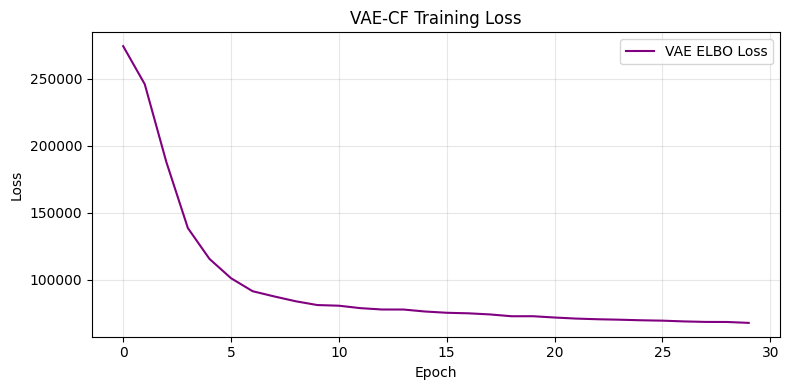

In [44]:
import matplotlib.pyplot as plt

# Loss 시각화
plt.figure(figsize=(8, 4))
plt.plot(vae_losses, color='purple', label='VAE ELBO Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('VAE-CF Training Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### **5-5. 추천 결과 확인**

In [45]:
vae.eval()
with torch.no_grad():
    h      = vae.encoder.layers(R_tensor)
    mu     = vae.encoder.mu_layer(h)
    recon  = vae.decoder(mu).cpu().numpy()

# NMF 추천 함수 재활용 (pred_df만 VAE 결과로 교체)
R_pred_vae = pd.DataFrame(recon, index=R_filled.index, columns=R_filled.columns)

# NMF는 4-3에서, VAE는 바로 위에서 만든 예측 행렬을 넣어 주세요
print("\n=== NMF 추천 결과 (userId=1) ===")
nmf_result = recommend_movies(R_pred_nmf, R, userId=1, top_n=5).rename(columns={'pred_rating': '예측 평점 (1~5)'})
print(nmf_result.to_string(index=False))

print("\n=== VAE 추천 결과 (userId=1) ===")
vae_result = recommend_movies(R_pred_vae, R, userId=1, top_n=5).rename(columns={'pred_rating': '시청 확률 (0~1)'})
print(vae_result.to_string(index=False))


=== NMF 추천 결과 (userId=1) ===
                       title  예측 평점 (1~5)
       Close Shave, A (1995)     3.743240
             Heathers (1989)     3.606087
Sense and Sensibility (1995)     3.531067
          Stand by Me (1986)     3.471248
        Trainspotting (1996)     3.395183

=== VAE 추천 결과 (userId=1) ===
                            title  시청 확률 (0~1)
E.T. the Extra-Terrestrial (1982)     0.922889
                     Speed (1994)     0.845672
                 True Lies (1994)     0.833357
                    Batman (1989)     0.826674
               Stand by Me (1986)     0.802596


---
### 아래는 두 과제, A와 B 중 하나를 선택하셔서 수행하시면 됩니다! (물론 둘 다 해봐도 됩니다.)

---

## **6-A. SASRec - 어텐션 추천시스템 실습**

OTT나 이커머스처럼, 시청/구매 순서를 보고 다음 콘텐츠나 상품을 제안하는 추천 시스템을 생각해 보세요!

Transformer 기반 순차 추천에서는 **"미래 정보를 보면 안 된다"** 는 원칙이 있습니다.

예를 들어 `[신발, 바지, 셔츠, ?]` 시퀀스에서 `?`를 예측할 때,  
모델이 학습 중에 미래 아이템을 미리 보고 예측하면 의미가 없으니까요!

이번 실습에서는 MovieLens 100K 데이터로 SASRec을 직접 학습하고,  
**"같은 유저라도 어떤 시청 이력을 넣느냐에 따라 추천이 달라진다"** 는 것을 확인합니다.

In [46]:
import os, random, urllib.request, zipfile, io
import numpy as np
import pandas as pd
from collections import defaultdict

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42) # 시드 고정함

# GPU 사용 가능 여부 확인
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'사용 디바이스: {device}')

사용 디바이스: cuda


### **Step 1. 데이터 로드 및 전처리**

MovieLens 100K를 로드합니다.
SASRec은 **"언제 봤는가"(즉 순서)** 가 중요하므로, timestamp 기준으로 정렬합니다.

- **Implicit feedback**: 평점 3점 이상 → 1 (봤다), 나머지 제외
- **ID 재매핑**: Embedding layer에 넣으려면 0~N-1 연속 id가 필요 (0은 padding 예약)

In [47]:
url = 'http://files.grouplens.org/datasets/movielens/ml-100k.zip'
with urllib.request.urlopen(url) as res:
    zf = zipfile.ZipFile(io.BytesIO(res.read()))

with zf.open('ml-100k/u.data') as f:
    df = pd.read_csv(f, sep='\t', names=['user', 'item', 'rating', 'timestamp'])

with zf.open('ml-100k/u.item') as f:
    item_meta = pd.read_csv(f, sep='|', encoding='latin-1', header=None, usecols=[0,1])
    item_meta.columns = ['item_raw', 'title']

df = df[df['rating'] >= 3]

user2id = {u: i+1 for i, u in enumerate(sorted(df['user'].unique()))}
item2id = {i: j+1 for j, i in enumerate(sorted(df['item'].unique()))}
df['user'] = df['user'].map(user2id)
df['item'] = df['item'].map(item2id)

n_users, n_items = df['user'].nunique(), df['item'].nunique()
print(f'유저 수: {n_users}, 아이템 수: {n_items}')

유저 수: 943, 아이템 수: 1574


### **Step 2. 유저별 시퀀스 생성 + Train/Val/Test 분할**

각 유저의 시청 이력을 시간순으로 정렬한 뒤 아래처럼 나눕니다.

| 분할 | 내용 |
|------|------|
| **train** | 전체 시퀀스에서 마지막 2개를 제외한 나머지 |
| **val** | 마지막에서 두 번째 아이템 |
| **test** | 마지막 아이템 |

In [48]:
df = df.sort_values(['user', 'timestamp'])

user_sequences = defaultdict(list)
for row in df.itertuples():
    user_sequences[row.user].append(row.item)

# 5개 미만 시청 유저 제거
user_sequences = {u: s for u, s in user_sequences.items() if len(s) >= 5}

user_train, user_val, user_test = {}, {}, {}
for u, seq in user_sequences.items():
    user_train[u] = seq[:-2]
    user_val[u]   = seq[-2]
    user_test[u]  = seq[-1]

print(f'학습 유저 수: {len(user_train)}')

학습 유저 수: 943


### **Step 3. Dataset 구성**

한 유저의 시퀀스 `[i1, i2, i3, i4]`로부터 아래처럼 학습 샘플을 만듭니다.

```
[i1]          → i2
[i1, i2]      → i3
[i1, i2, i3]  → i4
```

시퀀스 길이를 MAX_SEQ_LEN=50으로 고정하고, 짧은 경우 왼쪽을 0으로 패딩합니다.

In [49]:
MAX_SEQ_LEN = 50

class SASRecDataset(Dataset):
    def __init__(self, user_train_dict, max_len):
        self.seqs, self.targets = [], []
        for items in user_train_dict.values():
            if len(items) < 2:
                continue
            for t in range(1, len(items)):
                seq = items[:t][-max_len:]        # 최근 max_len개만 사용
                pad = [0] * (max_len - len(seq))  # 왼쪽 패딩
                self.seqs.append(pad + seq)
                self.targets.append(items[t])
        self.seqs    = torch.LongTensor(self.seqs)
        self.targets = torch.LongTensor(self.targets)

    def __len__(self): return len(self.targets)
    def __getitem__(self, idx): return self.seqs[idx], self.targets[idx]

train_dataset = SASRecDataset(user_train, MAX_SEQ_LEN)
train_loader  = DataLoader(train_dataset, batch_size=256, shuffle=True)
print(f'학습 샘플 수: {len(train_dataset)}')

학습 샘플 수: 79691


### **Step 4. SASRec 모델**

SASRec의 핵심은 **Causal Mask** 입니다.
현재 위치 t가 미래 위치(t+1, t+2, ...)를 보지 못하도록 상삼각 행렬로 막습니다.

```
위치:  0  1  2  3
  0  [ .  X  X  X ]   → 0번은 자신만 봄
  1  [ .  .  X  X ]   → 1번은 0, 1번만 봄
  2  [ .  .  .  X ]   → 2번은 0, 1, 2번만 봄
  3  [ .  .  .  . ]   → 3번은 전부 봄
X = 차단 (-inf 처리)
```

In [50]:
class SASRec(nn.Module):
    def __init__(self, n_items, d_model=64, n_layers=2, n_heads=2, max_len=50, dropout=0.2):
        super().__init__()
        self.item_emb = nn.Embedding(n_items+1, d_model, padding_idx=0)
        self.pos_emb  = nn.Embedding(max_len, d_model)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=n_heads,
            dim_feedforward=4*d_model, dropout=dropout, batch_first=True
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)
        self.dropout = nn.Dropout(dropout)
        self.norm    = nn.LayerNorm(d_model)
        self.output  = nn.Linear(d_model, n_items+1, bias=False)
        self.output.weight = self.item_emb.weight  # weight tying

        nn.init.normal_(self.item_emb.weight, std=0.01)
        nn.init.normal_(self.pos_emb.weight,  std=0.01)

    def forward(self, seq):
        B, L = seq.shape
        pos  = torch.arange(L, device=seq.device).unsqueeze(0).expand(B, L)
        x    = self.norm(self.dropout(self.item_emb(seq) + self.pos_emb(pos)))

        # Causal mask: 상삼각 True → 미래 차단
        causal_mask = torch.triu(torch.ones(L, L, device=seq.device), diagonal=1).bool()
        pad_mask    = (seq == 0)

        h = self.encoder(x, mask=causal_mask, src_key_padding_mask=pad_mask)
        return h

    def predict_next(self, seq):
        # 마지막 위치의 hidden state로 다음 아이템 예측
        return self.output(self.forward(seq)[:, -1, :])

model = SASRec(n_items=n_items, d_model=128, n_layers=3, n_heads=4,
                max_len=MAX_SEQ_LEN, dropout=0.3).to(device)

### **Step 5. 평가 지표: Recall@K, NDCG@K**

| 지표 | 의미 |
|------|------|
| **Recall@K** | 정답 아이템이 Top-K 안에 들어있으면 1, 아니면 0 |
| **NDCG@K** | 정답 아이템의 순위가 높을수록 더 큰 점수 부여 |

In [51]:
def evaluate(model, user_train, user_eval, k=20):
    model.eval()
    recalls, ndcgs = [], []

    with torch.no_grad():
        for u, train_items in user_train.items():
            target = user_eval.get(u)
            if not target:
                continue

            seq = train_items[-MAX_SEQ_LEN:]
            seq = [0] * (MAX_SEQ_LEN - len(seq)) + seq
            seq_t = torch.LongTensor(seq).unsqueeze(0).to(device)

            scores = model.predict_next(seq_t).squeeze(0).cpu().numpy()
            scores[0] = -1e9
            for item in train_items:
                scores[item] = -1e9

            rank = int(np.where(np.argsort(-scores) == target)[0][0])
            recalls.append(1.0 if rank < k else 0.0)
            ndcgs.append(1.0 / np.log2(rank + 2) if rank < k else 0.0)

    print(f'Recall@{k}: {np.mean(recalls):.4f} | NDCG@{k}: {np.mean(ndcgs):.4f}')
    return np.mean(recalls), np.mean(ndcgs)

### **Step 6. 학습**

In [52]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)

best_recall, best_state = 0.0, None
patience     = 10   # 성능 개선 없이 허용할 최대 epoch 수
no_improve   = 0    # 성능 개선 없는 epoch 카운트

for epoch in range(1, 51):
    model.train()
    total_loss = 0
    for seq_b, target_b in train_loader:
        seq_b, target_b = seq_b.to(device), target_b.to(device)
        loss = criterion(model.predict_next(seq_b), target_b)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * seq_b.size(0)

    print(f'[Epoch {epoch:2d}] 학습 손실: {total_loss/len(train_dataset):.4f}', end='  ')
    recall, _ = evaluate(model, user_train, user_val)

    if recall > best_recall:
        best_recall = recall
        best_state  = {k: v.cpu() for k, v in model.state_dict().items()}
        no_improve  = 0
        print('  ← best!')
    else:
        no_improve += 1
        if no_improve >= patience:
            print(f'\n조기 종료: {patience}epoch 동안 성능 개선 없음')
            break

# best 모델 로드 후 최종 평가
model.load_state_dict(best_state)
model.to(device)
print('\n=== 최종 Test 성능 ===')
evaluate(model, user_train, user_test)

[Epoch  1] 학습 손실: 6.3740  Recall@20: 0.1018 | NDCG@20: 0.0401
  ← best!
[Epoch  2] 학습 손실: 5.8652  Recall@20: 0.1166 | NDCG@20: 0.0501
  ← best!
[Epoch  3] 학습 손실: 5.7612  Recall@20: 0.1241 | NDCG@20: 0.0524
  ← best!
[Epoch  4] 학습 손실: 5.6975  Recall@20: 0.1304 | NDCG@20: 0.0570
  ← best!
[Epoch  5] 학습 손실: 5.6446  Recall@20: 0.1347 | NDCG@20: 0.0503
  ← best!
[Epoch  6] 학습 손실: 5.5953  Recall@20: 0.1453 | NDCG@20: 0.0588
  ← best!
[Epoch  7] 학습 손실: 5.5526  Recall@20: 0.1347 | NDCG@20: 0.0543
[Epoch  8] 학습 손실: 5.5140  Recall@20: 0.1336 | NDCG@20: 0.0559
[Epoch  9] 학습 손실: 5.4810  Recall@20: 0.1400 | NDCG@20: 0.0633
[Epoch 10] 학습 손실: 5.4527  Recall@20: 0.1474 | NDCG@20: 0.0616
  ← best!
[Epoch 11] 학습 손실: 5.4248  Recall@20: 0.1463 | NDCG@20: 0.0612
[Epoch 12] 학습 손실: 5.4014  Recall@20: 0.1400 | NDCG@20: 0.0613
[Epoch 13] 학습 손실: 5.3767  Recall@20: 0.1538 | NDCG@20: 0.0608
  ← best!
[Epoch 14] 학습 손실: 5.3591  Recall@20: 0.1336 | NDCG@20: 0.0588
[Epoch 15] 학습 손실: 5.3380  Recall@20: 0.1347 | NDCG@2

(np.float64(0.12937433722163308), np.float64(0.0529908640353969))

### **Step 7. 추천 결과 확인**

같은 유저라도 **어떤 시청 이력을 입력하느냐에 따라 추천이 달라집니다.**
초반 이력만 넣었을 때와 전체 이력을 넣었을 때를 비교해봅시다.

In [53]:
# 내부 아이템 id → 영화 제목 매핑
id2raw   = {v: k for k, v in item2id.items()}
id2title = {inner: item_meta.set_index('item_raw').loc[raw, 'title']
            for inner, raw in id2raw.items()
            if raw in item_meta['item_raw'].values}

In [54]:
def recommend(seq, topk=10):
    model.eval()
    with torch.no_grad():
        s = seq[-MAX_SEQ_LEN:]
        s = [0] * (MAX_SEQ_LEN - len(s)) + s
        scores = model.predict_next(
            torch.LongTensor(s).unsqueeze(0).to(device)
        ).squeeze(0).cpu().numpy()
        scores[0] = -1e9
        for item in seq:
            scores[item] = -1e9
        return np.argsort(-scores)[:topk]

def compare_prefix(user_id, cut_ratio=0.5, topk=10):
    from IPython.display import display

    full = user_train[user_id]
    cut  = max(1, int(len(full) * cut_ratio))

    recent     = [id2title.get(i, f'item_{i}') for i in full[-10:]][::-1]
    early_recs = [id2title.get(i, f'item_{i}') for i in recommend(full[:cut], topk)]
    full_recs  = [id2title.get(i, f'item_{i}') for i in recommend(full, topk)]

    print(f'=== User {user_id} 최근 시청 ===')
    display(pd.DataFrame({
    '순서 (최근순)': range(1, len(recent)+1),
    '영화 제목': recent
    }).set_index('순서 (최근순)'))

    print(f'\n=== 초반 {cut}편 기준 vs 전체 {len(full)}편 기준 추천 비교 ===')
    display(pd.DataFrame({
    '순위': range(1, topk+1),
    f'초반 {cut}편 기준 추천': early_recs,
    f'전체 {len(full)}편 기준 추천': full_recs
    }).set_index('순위'))

In [55]:
# 실행하기

sample_user = list(user_train.keys())[10]
compare_prefix(sample_user, cut_ratio=0.4, topk=10)

=== User 11 최근 시청 ===


,영화 제목
순서 (최근순),
1,Benny & Joon (1993)
2,Pretty Woman (1990)
3,Shadowlands (1993)
4,"Room with a View, A (1986)"
5,Enchanted April (1991)
6,"Last of the Mohicans, The (1992)"
7,"Client, The (1994)"
8,Star Trek: The Motion Picture (1979)
9,Body Snatchers (1993)



=== 초반 62편 기준 vs 전체 156편 기준 추천 비교 ===


,초반 62편 기준 추천,전체 156편 기준 추천
순위,,
1,"Remains of the Day, The (1993)","Age of Innocence, The (1993)"
2,Field of Dreams (1989),Grease (1978)
3,Quiz Show (1994),"Bridges of Madison County, The (1995)"
4,"Piano, The (1993)",It Could Happen to You (1994)
5,"Graduate, The (1967)",Dirty Dancing (1987)
6,Like Water For Chocolate (Como agua para choco...,Legends of the Fall (1994)
7,Gandhi (1982),Don Juan DeMarco (1995)
8,My Left Foot (1989),Muriel's Wedding (1994)
9,What's Eating Gilbert Grape (1993),Some Kind of Wonderful (1987)


## **과제 6-B. 하이브리드 추천 시스템 아키텍처 설계**

여러분은 다음 달 오픈하는 이커머스 플랫폼 **인사이트 쇼핑**의 추천 시스템 설계를 맡게 되었습니다.
기획팀에서 아래와 같은 검토 요청서가 전달되었습니다. 요청서를 읽고 **추천 시스템 도입안**을 작성해 주세요.


> ### 추천 시스템 도입 검토 요청서
>
> **작성**: 인사이트 쇼핑 기획팀 · **수신**: 추천 시스템 담당자
>
> **1. 서비스 현황**
> - 등록 상품 약 300만 개, 오픈 시점 예상 회원 수 약 5만 명
> - 현재 메인 화면 추천 로직: "지난주 판매량 상위 20개를 모든 회원에게 동일하게 노출"
>
> **2. 제약 사항**
> - 추천 서버에 배정된 GPU는 1대입니다. 요청이 들어올 때마다 300만 개 상품 전체에 딥러닝 연산을 수행하는 방식은 감당할 수 없습니다.
>
> **3. 요청 사항**
> - **오픈 당일**에는 구매 기록이 없는 신규 회원과, 리뷰·판매 이력이 없는 신규 상품만 존재합니다. 이 상황에서도 추천이 동작해야 합니다.
> - 베타 테스트에서 "메인에 뜨는 상품이 매번 똑같다"는 의견이 가장 많았습니다. 인기 상품만 반복해서 노출되는 현상을 완화할 방안이 필요합니다.
>
> **4. 비고**
> - 정답이 정해진 문제는 아니며, 제안의 근거를 함께 적어 주시면 됩니다.

---

### **조건 1. 2단계 파이프라인 설계**

300만 개 상품 중 최종 노출할 수십 개를 고르는 과정을 두 단계로 나눠 설계해 주세요.

**1단계: 후보군 생성** (300만 개 → 수백 개)

- **알고리즘**: 모델 기반 협업 필터링 (행렬 분해)
- **이유**: 회원·상품 잠재 벡터를 미리 학습해 두고, 추천할 땐 벡터 내적만 계산해서 빠름. GPU 1대로 300만 개 전부 딥러닝 돌리는 건 불가능하니 가벼운 모델로 먼저 거름

**2단계: 순위 매기기** (수백 개 → 최종 노출)

- **알고리즘**: VAE 기반 협업 필터링
- **이유**: 오픈 초기라 회원당 구매 기록이 적음. VAE는 취향을 분포로 표현하고 KL 항이 잠재 공간을 정규분포 근처로 모아줘서, 기록 적은 회원도 비슷한 회원들 근처에 안정적으로 놓임. 후보 수백 개에만 돌리니까 GPU 1대로 충분함

### **조건 2. 콜드 스타트 대응**

**유저 콜드 스타트**
- 가입할 때 관심 카테고리·브랜드를 직접 고르게 해서 첫 추천 근거로 씀
- 나이·성별 같은 인구통계 정보로 비슷한 회원 그룹을 추정하고, 그 그룹이 많이 산 상품을 추천함
- 구매·클릭 기록이 쌓이면 행렬 분해와 VAE 추천으로 넘어감

**아이템 콜드 스타트**
- 판매 이력은 없어도 카테고리, 상품명, 설명 글은 있으니 내용 기반 필터링으로 비슷한 상품을 찾아 후보에 올림
- 1단계 행렬 분해에서 쓰는 상품 벡터가 아직 없으니, 같은 카테고리 상품들의 벡터 평균으로 임시 벡터를 만들어서 바로 후보군에 포함시킴



### **조건 3. 인기 편향 완화**

**발생 원인**
- 지금은 지난주 판매량 상위 20개를 전 회원에게 똑같이 보여줘서, 노출이 처음부터 인기 상품에 몰림
- 그러면 구매, 클릭 기록도 인기 상품에만 쌓임 (데이터 불균형)
- 1단계 행렬 분해, 2단계 VAE 둘 다 기록 기반 협업 필터링이라 기록 많은 상품 점수가 더 높게 나옴
- 추천 -> 노출 -> 클릭 -> 재학습 반복되면서 격차가 계속 커짐 

**완화 전략**
- 1단계 후보군 수백 개 중 일부를 내용 기반 필터링으로 채움. 다른 회원 구매 기록이 아니라 상품 정보로 고르니까 비인기/신규 상품도 후보에 들어감
- 메인 화면 노출 칸 일부를 신규/비인기 상품 전용으로 따로 배정함. 노출 기회가 생겨야 기록이 쌓이고, 그래야 협업 필터링에서도 추천될 수 있음


> 💡 힌트: 강의에서 배운 추천 방법 중, 다른 사용자들의 구매·클릭 기록에 덜 의존하는 방법은 무엇이었나요? 2단계 파이프라인의 어느 단계에서 활용할 수 있을지 생각해 보세요.

# 😊 수고하셨습니다 ~~~